In [85]:
import cobra
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('/home/nathan/PhD/04.Computational/202601_13C/3_src/')
sys.path.append('../3_src/')
import analysis.io_func as io_func

import os

import gurobipy as gp
import re
from analysis import config_pta as cfp
from cmap import Colormap

from analysis.DistribComp import DistribComparer

# how to make a feasible hit run sampler, using gurobi model to sort out infeasible cases

In [86]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()


## get  model for S matrix

In [87]:
cmodel=cobra.io.read_sbml_model(f'{cfp.SYNDATA_FOLDER}/cobra_roundp3_ymodel.xml')
S=cobra.util.array.create_stoichiometric_matrix(cmodel)

In [88]:
ignore_mets=[m.id for m in cmodel.reactions.biomass_c.metabolites]
ignore_mets

['proteins_c',
 'lipids_c',
 'polysacch_c',
 'dna_c',
 'rna_c',
 'storage_c',
 'biomass_c',
 'h_c']

## load results
##from all samples df, make one big df with all samples 
##concat cols basically

In [89]:
def read_sample_cols(folder,tot_nsamples,accepted_samples=None,seed=33,hd5=False):
    rangen=np.random.default_rng(seed)
    dfs=[]
    size_pfile=int(tot_nsamples/len(accepted_samples)) if accepted_samples is not None else int(tot_nsamples/50)
    if accepted_samples is None:
          accepted_samples= range(1000)
    for file in [f for f in os.listdir(folder) 
                 if re.search(r'sample(\d+)', f).group(1) in map(str, accepted_samples) ### search pattern if sample is in accepted samples
                   ]:
            if hd5 :
                 df= pd.read_hdf(os.path.join(folder, file), key='data').T
            else : 
                  df = pd.read_csv(os.path.join(folder, file), index_col=0).T ### in previous 
            
            # sample columns from this file
            n_cols_to_sample = min(size_pfile, df.shape[1])  # safety
            sampled_cols = rangen.choice(df.columns, size=n_cols_to_sample, replace=False)
            
            dfs.append(df[sampled_cols])
            
    return pd.concat(dfs, axis=1)

In [90]:
def bootstrap_flux_df(condition, samples_as_cols=False):
    """Load weighted flux df, optionally using sample acutal numbers as columns."""

    if not samples_as_cols:
        flux_df = pd.read_csv(
            f'{cfp.RES_13C_FOLDER}/bootstrap_flux_df_{condition}.csv',
            index_col=0
        )
    else:
        raw = pd.read_csv(
            f'{cfp.RES_13C_FOLDER}/bootstrap_flux_df_{condition}.csv',
            header=None,
            dtype=str
        )

        flux_df = raw.iloc[1:].copy()
        flux_df.columns = raw.iloc[0]
        flux_df = flux_df.set_index(flux_df.columns[0])
        flux_df.columns.name = None
        flux_df.index.name = None
        flux_df.columns=[int(c) for c in flux_df.columns    ]


        flux_df = flux_df.apply(pd.to_numeric, errors='coerce')

    return flux_df

In [91]:
# ###wT
# size=int(5e5)
# # df_wt_plot=ran_gen.choice(df_wt_accepted,size=size,axis=1)
 ##flux bounds  
condition=cond='WT'

prep=cfp.config_prep(cond)

bootstrap_flux_dfwt=bootstrap_flux_df(condition,samples_as_cols=True)

chosen_samples_wt=bootstrap_flux_dfwt.columns


df_wt_plot=read_sample_cols(cfp.METSAMPLING_FOLDER+str(f'/{condition}/'),1000000,accepted_samples=chosen_samples_wt,seed=33,hd5=True)
df_wt_plot

removing ['Galkin', 'Gal7', 'Gal10', 'Mankin', 'M6pism', 'MALTGD', 'gal-D_EX', 'man-D_EX', 'malt_EX', 'GALt+0', 'Mant+0', 'MALTt+1']
no met data for ppi_c 'ppi'
no met data for 4pasp_c '4pasp'
no met data for oaa_c 'oaa'
no met data for oaa_m 'oaa'
no met data for nadph_c 'nadph'
no met data for aspsa_c 'aspsa'
no met data for pi_c 'pi'
no met data for pyr_c 'pyr'
no met data for pyr_m 'pyr'
no met data for glycogen_c 'glycogen'
no met data for g1p_c 'g1p'
no met data for glx_c 'glx'
no met data for hco3_m 'hco3'
nadph_m ignored because we set constraint on redox ratio
no met data for hco3_c 'hco3'
no met data for acglu_m 'acglu'
no met data for acg5p_m 'acg5p'
no met data for acg5sa_m 'acg5sa'
no met data for acorn_m 'acorn'
no met data for argsuc_c 'argsuc'
no met data for arg-L_c 'arg-L'
no met data for citr-L_c 'citr-L'
no met data for cbp_c 'cbp'
no met data for glu5p_c 'glu5p'
no met data for pi_m 'pi'
no met data for 10fthf_c '10fthf'
no met data for thf_c 'thf'
no met data for 

,36132,95619,21504,1097,30306,58420,44060,87350,4292,55204,...,12654,34036,62910,50356,19744,49365,81994,40075,350,71070
asp-L_c,-4.455397,-4.557428,-4.694093,-4.612930,-4.414292,-4.575472,-4.911233,-4.779912,-4.829468,-5.026263,...,-4.495407,-4.724426,-4.512269,-4.963689,-4.931964,-4.237751,-4.375512,-4.687535,-4.496539,-4.194105
atp_c,-6.934538,-6.733744,-6.760994,-5.861027,-5.987648,-6.425780,-6.306089,-6.476050,-6.130515,-6.400286,...,-6.952960,-6.396007,-6.098389,-6.128418,-6.134569,-6.654256,-6.825930,-6.714854,-6.573525,-6.112924
gln-L_c,-3.795256,-4.097970,-3.652743,-3.648684,-4.500714,-3.959976,-3.933663,-3.960517,-4.113248,-4.635436,...,-3.989443,-4.409787,-3.743886,-3.833496,-4.467041,-4.492388,-4.558319,-4.043088,-3.972844,-3.719062
amp_c,-9.694504,-10.287735,-10.360264,-9.124727,-9.450596,-9.965631,-9.626320,-8.625311,-10.000937,-9.283253,...,-9.971783,-9.234804,-9.524929,-8.895285,-9.819862,-10.274686,-9.733755,-9.692523,-10.126650,-9.210095
asn-L_c,-6.793293,-7.247058,-6.533965,-6.016410,-6.807997,-7.054156,-6.373287,-6.561448,-5.926490,-5.861163,...,-6.326589,-6.600474,-6.268210,-6.437980,-7.041926,-6.900956,-5.921049,-5.918988,-7.462343,-6.219252
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
pyr_e,-9.673854,-8.798055,-8.269386,-6.808950,-8.086900,-8.548534,-7.680376,-9.854824,-8.228210,-8.868520,...,-7.315903,-8.276859,-8.936707,-8.475675,-7.745349,-9.028770,-7.207179,-9.704345,-8.886961,-8.290633
so4_e,-7.137567,-8.625301,-8.148948,-7.970259,-9.031172,-7.591631,-9.100738,-7.733839,-8.795891,-9.379912,...,-7.136357,-7.806840,-7.399317,-7.094053,-8.856322,-6.865273,-8.244919,-6.294355,-7.416507,-10.489887
succ_e,-7.965911,-7.294042,-7.334772,-7.266239,-7.680829,-7.244537,-7.198679,-7.212927,-7.358401,-7.337901,...,-7.559015,-7.564924,-6.856867,-7.236154,-7.979607,-8.457578,-7.769639,-7.010834,-6.961137,-7.855446
ficytc_c,2.235635,2.368137,2.537776,2.770748,3.908455,4.494836,3.072691,1.975804,3.734092,3.410697,...,3.716344,2.974627,2.216581,3.246343,2.430141,3.369386,3.104587,3.078164,2.099028,2.299736


In [115]:
bootstrap_flux_dfwt.loc['PPCK'].describe()

count    100.000000
mean       0.387924
std        0.306078
min        0.011890
25%        0.079869
50%        0.254000
75%        0.715970
max        0.772770
Name: PPCK, dtype: float64

In [92]:
cond=condition='TM6'
obj_vals=pd.read_csv(f'{cfp.RES_13C_FOLDER}/objvals_{cond}.csv',index_col=0) #pd.read_csv(cfp.RES_13C_FOLDER/  ,index_col=0)

bootstrap_flux_dftm6=bootstrap_flux_df(condition,samples_as_cols=True)
bootstrap_flux_dftm6=bootstrap_flux_dftm6.drop(columns=663)

chosen_samples_tm6=bootstrap_flux_dftm6.columns
 
df_tm6_plot=read_sample_cols(cfp.METSAMPLING_FOLDER+str(f'{condition}/'),1000000,chosen_samples_tm6,seed=33,hd5=True,)

preptm6=cfp.config_prep(cond)

removing ['Galkin', 'Gal7', 'Gal10', 'Mankin', 'M6pism', 'MALTGD', 'gal-D_EX', 'man-D_EX', 'malt_EX', 'GALt+0', 'Mant+0', 'MALTt+1']
no met data for ppi_c 'ppi'
no met data for 4pasp_c '4pasp'
no met data for oaa_c 'oaa'
no met data for oaa_m 'oaa'
no met data for nadph_c 'nadph'
no met data for aspsa_c 'aspsa'
no met data for pi_c 'pi'
no met data for pyr_c 'pyr'
no met data for pyr_m 'pyr'
no met data for glycogen_c 'glycogen'
no met data for g1p_c 'g1p'
no met data for glx_c 'glx'
no met data for hco3_m 'hco3'
nadph_m ignored because we set constraint on redox ratio
no met data for hco3_c 'hco3'
no met data for acglu_m 'acglu'
no met data for acg5p_m 'acg5p'
no met data for acg5sa_m 'acg5sa'
no met data for acorn_m 'acorn'
no met data for argsuc_c 'argsuc'
no met data for arg-L_c 'arg-L'
no met data for citr-L_c 'citr-L'
no met data for cbp_c 'cbp'
no met data for glu5p_c 'glu5p'
no met data for pi_m 'pi'
no met data for 10fthf_c '10fthf'
no met data for thf_c 'thf'
no met data for 

## first : which metabolites have altered ranges compared to initial bounds

In [93]:
## func to get min and max from sampled met bounds 
def get_sampledboudns(df_sample):
    dfboudns= pd.concat([df_sample.min(axis=1),df_sample.max(axis=1)],axis=1)
    dfboudns.columns=['lb','ub']
    dfboudns['range']=dfboudns['ub']-dfboudns['lb']
    return dfboudns

df_samp_wt=get_sampledboudns(df_wt_plot)
df_samp_tm6=get_sampledboudns(df_tm6_plot)
# df_samp=get_sampledboudns(df_plot)

In [94]:
###distribution of initial  bounds using prep.log_conc_cov and mean
lnc_mean=prep.log_conc_mean
lnc_cov=prep.log_conc_cov
# draw many samples (e.g., 1000)
gaussian_samples_lnc = pd.DataFrame(np.random.multivariate_normal(mean=lnc_mean, cov=lnc_cov, size=10000)).T
df_init_bounds=get_sampledboudns(gaussian_samples_lnc)
df_init_bounds.index=prep.S_df_constrained_redmets.index
df_init_bounds=df_init_bounds.loc[[i for i in prep.S_df_constrained_redmets.index if i not in ignore_mets]]

In [95]:
#same for tm6 ##similiar ranges than wt## but still do it for its own comparer later
lnc_meantm6=preptm6.log_conc_mean
lnc_covtm6=preptm6.log_conc_cov
# draw many samples (e.g., 1000)
gaussian_samples_lnctm6 = pd.DataFrame(np.random.multivariate_normal(mean=lnc_meantm6, cov=lnc_covtm6, size=10000)).T
df_init_bounds_tm6=get_sampledboudns(gaussian_samples_lnctm6)
df_init_bounds_tm6.index=preptm6.S_df_constrained_redmets.index
df_init_bounds_tm6=df_init_bounds_tm6.loc[[i for i in preptm6.S_df_constrained_redmets.index if i not in ignore_mets]]

which pathways are the metabolties from ?

In [96]:
pathways_mapping=pd.read_csv(f'{cfp.SYNDATA_FOLDER}/pathways_mapping.csv',index_col=0)
## func to check reactions of a metabolite and correspoinding subsytem then take the major subsytem
def met_pathway(met,p_map=pathways_mapping):
    rxns_id=[i.id for i in met.reactions if i.id in p_map.index]
    paths=p_map.loc[rxns_id].value_counts().index
    try : 
        paths=paths.drop('Transport, mM')
    except:
        pass
    try : 
        return paths[0][0] if 'nad' not in met.id else 'Redox metabolism'
    except:
        return None
met_path_mapping={met.id:met_pathway(met) for met in cmodel.metabolites}
##replace biomass synthesis with biosynthesis in the dict
met_path_mapping = {k: v.replace("Biomass synthesis", "Biosynthesis") if isinstance(v, str) else v
           for k, v in met_path_mapping.items()}

/tmp/ipykernel_1457786/815114348.py:7: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  paths=paths.drop('Transport, mM')
/tmp/ipykernel_1457786/815114348.py:7: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  paths=paths.drop('Transport, mM')
/tmp/ipykernel_1457786/815114348.py:7: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  paths=paths.drop('Transport, mM')
/tmp/ipykernel_1457786/815114348.py:7: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  paths=paths.drop('Transport, mM')
/tmp/ipykernel_1457786/815114348.py:7: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  paths=paths.drop('Transport, mM')
/tmp/ipykernel_1457786/815114348.py:7: PerformanceWarning: dropping on a no

In [97]:
pd.Series(met_path_mapping).value_counts()

Biosynthesis                                          47
Transport, Extracellular                              21
Valine, leucine, and isoleucine metabolism            15
Tyrosine, Tryptophan, and Phenylalanine Metabolism    15
Arginine and Proline Metabolism                       14
Oxidative phosphorylation                             12
Threonine and Lysine Metabolism                       11
Citrate Cycle (TCA)                                   10
Alternate Carbon Metabolism                            9
Alanine and aspartate metabolism                       8
Pyruvate metabolism                                    8
Redox metabolism                                       8
Glycolysis/Gluconeogenesis                             7
Histidine Metabolism                                   6
Pentose Phosphate Cycle                                6
Glycine and Serine Metabolism                          6
Glycerolipid Metabolism                                4
Galactose degradation          

## check distribution that are very different between WT and TM6

In [101]:
##condition sample dist
dist1=df_wt_plot.sample(1000,axis=1)
dist2=df_tm6_plot.sample(1000,axis=1)


In [102]:
distcomp=DistribComparer(dist1,dist2,num_points=10000)

In [103]:
deltamean=distcomp.get_deltamean()
overlap_all=distcomp.compute_overlap_all(align=False)

In [104]:
ser_area=pd.Series(overlap_all)
ser_area_opp=pd.Series([1-x for x in ser_area],index=ser_area.index)


In [105]:
###dont count met whose conc can be free
ser_area_opp_plot=ser_area_opp.loc[[i for i in ser_area_opp.index if i in prep.S_df_constrained_redmets.index and i not in ignore_mets]]
 

In [106]:
# ser_area_opp_plot.index=[cmodel.metabolites[int(i)].id for i in ser_area_opp_plot.index]
ser_area_opp_plot.sort_values(ascending=True).head(20)#.index

2ippm_c     0.020550
phpyr_c     0.023035
10fthf_c    0.024312
methf_c     0.024958
3ig3p_c     0.026595
4mop_c      0.027360
2obut_m     0.027840
o2_c        0.028278
prlp_c      0.028501
skm_c       0.028890
3c2hmp_c    0.029594
pap_c       0.030148
prpp_c      0.030306
tre_c       0.031021
arg-L_c     0.031419
argsuc_c    0.031493
ac_m        0.031996
damp_c      0.032133
34hpp_c     0.032183
mlthf_c     0.033049
dtype: float64

first plot is a hist plot of overlap areas with zoom in on comparison for one specific metabolite 

Text(0, 0.5, 'Count')

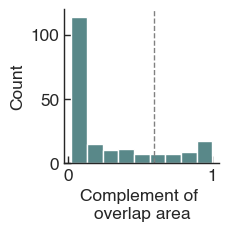

In [107]:
(ser_area_opp_plot > 0.5).sum()/len(ser_area_opp_plot)
fig, ax = plt.subplots(1, figsize=(2,2))
io_func.scale_rcparams(fig, scalingf=0.5)
sns.histplot(ser_area_opp_plot,ax=ax)
##plot 80% percentile as vline 
ax.axvline(ser_area_opp_plot.quantile(0.8),color='grey',linestyle='--',linewidth=1)
ax.set_xlabel('Complement of \noverlap area')
ax.set_ylabel('Count')
# #save fig
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig7_histplot_distcomp_wtvtm6.png',bbox_inches='tight',dpi=300)
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig7_histplot_distcomp_wtvtm6.svg',bbox_inches='tight',dpi=300)


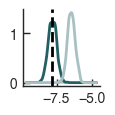

In [ ]:
fig,ax=plt.subplots(1,figsize=(1,1))
met='mal-L_m'
distcomp.plot_reaction(ax,met,align=False)
##set xticksa dn yticks fontsize to 10
ax.tick_params(axis='x',labelsize=10)
ax.tick_params(axis='y',labelsize=10)
#save fig
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig7_distcomp_met{met}.png',bbox_inches='tight',dpi=300)
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig7_distcomp_met{met}.svg',bbox_inches='tight',dpi=300)


## because met concentrations are log normal, we can just compare means

In [24]:
cm = Colormap('crameri:batlow')  
colors = cm(np.linspace(0, 1, 8))

/tmp/ipykernel_1457786/4238205719.py:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(mean_wt.loc[top_var_met],mean_tm6.loc[top_var_met],c=colors[1],s=10)


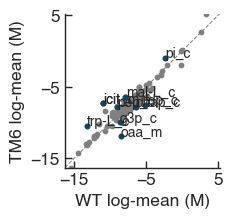

In [ ]:
mean_tm6=df_tm6_plot.mean(axis=1)
mean_wt=df_wt_plot.mean(axis=1)
#
fig, ax = plt.subplots(1, figsize=(2,2))
io_func.scale_rcparams(fig, scalingf=0.5)
##scatters : grey for all and colored for top diff
ax.scatter(mean_wt,mean_tm6,s=10,c='grey')
##top diff
top_var_met=ser_area_opp_plot.sort_values(ascending=False).head(10).index
ax.scatter(mean_wt.loc[top_var_met],mean_tm6.loc[top_var_met],c=colors[1],s=10)

##annotate
for met in top_var_met[:10]:
    ax.annotate(met, (mean_wt.loc[met]+0.04,mean_tm6.loc[met]+0.04), fontsize=10)


# ##plot a particular met in red
# ax.scatter(mean_wt.loc['cit_c'],mean_tm6.loc['cit_c'],c='red',s=10)
#format
axmin=min(min(mean_tm6),min(mean_wt))
axmax=max(max(mean_wt),max(mean_tm6))
ax.set_ylim(axmin,axmax)
ax.set_xlim(axmin,axmax)
ax.plot([0,1],[0,1],transform=ax.transAxes,**cfg['settings_diagonal'])
ax.set_xticks([-15,-5,5])
ax.set_yticks([-15,-5,5])
ax.set_xlabel('WT log-mean (M)')
ax.set_ylabel('TM6 log-mean (M)')

#save fig
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig7_boostrap_lnconc_mean_wtvtm6.png',bbox_inches='tight',dpi=300)
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig7_boostrap_lnconc_mean_wtvtm6.svg',bbox_inches='tight',dpi=300)
